# Import Libraries

In [ ]:


import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Train Test Split
from sklearn.model_selection import train_test_split

# Display Options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Plot Style
plt.style.use('ggplot')
sns.set_theme(style="whitegrid")



# Load Dataset

In [ ]:


df = pd.read_csv("student_performance_balanced.csv")



# Dataset Overview

In [ ]:
print("Shape of Dataset:")
print(df.shape)



Shape of Dataset:
(30000, 22)


In [ ]:

print("First Five Rows")
df.head()


First Five Rows


,Age,Grade,Gender,Race,SES_Quartile,ParentalEducation,SchoolType,Locale,TestScore_Math,TestScore_Reading,TestScore_Science,GPA,AttendanceRate,StudyHours,InternetAccess,Extracurricular,PartTimeJob,ParentSupport,Romantic,FreeTime,GoOut,Performance
0,17,12,Female,Black,1,HS,Public,Suburban,68.280990,67.686488,75.293605,2.450311,0.873647,1.038520,1,0,0,1,0,2,2,0
1,17,12,Female,Hispanic,4,Bachelors+,Public,City,100.000000,100.000000,97.782078,3.969801,1.000000,1.104243,1,1,0,1,0,1,1,2
2,15,10,Female,White,4,HS,Public,City,88.236842,95.322476,94.413480,4.000000,0.980589,1.376388,1,0,0,0,0,3,2,2
3,16,11,Male,Black,4,Bachelors+,Public,Rural,85.195279,82.700191,78.184216,3.581621,0.923087,0.631498,1,0,0,0,0,4,3,2
4,14,9,Male,Asian,3,<HS,Private,Suburban,65.059639,64.634338,61.016106,2.448366,0.829742,0.105131,1,1,0,0,0,3,1,0


In [ ]:
print("Last Five Rows")
display(df.tail())

Last Five Rows


,Age,Grade,Gender,Race,SES_Quartile,ParentalEducation,SchoolType,Locale,TestScore_Math,TestScore_Reading,TestScore_Science,GPA,AttendanceRate,StudyHours,InternetAccess,Extracurricular,PartTimeJob,ParentSupport,Romantic,FreeTime,GoOut,Performance
29995,14,9,Female,Hispanic,4,Bachelors+,Public,City,79.414147,84.708191,79.370996,3.636906,0.902535,0.834392,1,1,0,0,0,2,2,2
29996,17,12,Female,Asian,2,HS,Public,Town,60.280691,57.866856,67.642575,1.937750,0.798700,1.108122,1,1,0,0,0,3,2,0
29997,16,11,Male,White,2,HS,Private,City,71.074919,62.604131,62.975227,2.095396,0.869535,0.871842,0,0,0,0,1,4,2,0
29998,18,12,Male,White,1,HS,Private,Suburban,80.550115,84.382104,79.424926,3.372928,0.906675,1.181757,1,1,0,0,0,4,2,1
29999,15,10,Male,Black,2,HS,Public,Rural,90.678097,84.438689,83.524637,4.000000,0.979426,1.416042,1,0,0,1,0,4,2,2


# Dataset Information

In [ ]:
print("Dataset Information")

df.info()

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                30000 non-null  int64  
 1   Grade              30000 non-null  int64  
 2   Gender             30000 non-null  object 
 3   Race               30000 non-null  object 
 4   SES_Quartile       30000 non-null  int64  
 5   ParentalEducation  30000 non-null  object 
 6   SchoolType         30000 non-null  object 
 7   Locale             30000 non-null  object 
 8   TestScore_Math     30000 non-null  float64
 9   TestScore_Reading  30000 non-null  float64
 10  TestScore_Science  30000 non-null  float64
 11  GPA                30000 non-null  float64
 12  AttendanceRate     30000 non-null  float64
 13  StudyHours         30000 non-null  float64
 14  InternetAccess     30000 non-null  int64  
 15  Extracurricular    30000 non-null  int64  
 16  Pa

# Data Types


In [ ]:
dtype_df = pd.DataFrame(df.dtypes, columns=['Data Type'])

display(dtype_df)

,Data Type
Age,int64
Grade,int64
Gender,object
Race,object
SES_Quartile,int64
ParentalEducation,object
SchoolType,object
Locale,object
TestScore_Math,float64
TestScore_Reading,float64


# Numerical Summary

In [ ]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,30000.0,15.995400,1.417408,14.000000,15.000000,16.000000,17.000000,18.000000
Grade,30000.0,10.793700,1.166784,9.000000,10.000000,11.000000,12.000000,12.000000
SES_Quartile,30000.0,2.503233,1.117750,1.000000,2.000000,3.000000,4.000000,4.000000
TestScore_Math,30000.0,74.916842,11.793827,34.258722,66.199079,74.939559,83.711061,100.000000
TestScore_Reading,30000.0,74.915269,11.856854,31.912832,66.221127,74.971917,83.655705,100.000000
TestScore_Science,30000.0,74.939735,11.803580,30.760953,66.263518,75.027906,83.658046,100.000000
GPA,30000.0,2.992235,0.631761,1.140091,2.419079,2.997897,3.578877,4.000000
AttendanceRate,30000.0,0.898852,0.057127,0.700000,0.855662,0.899965,0.942856,1.000000
StudyHours,30000.0,0.999661,0.369151,0.000000,0.747724,1.001312,1.251418,2.355942
InternetAccess,30000.0,0.848667,0.358379,0.000000,1.000000,1.000000,1.000000,1.000000


# Categorical Summary

In [ ]:
display(df.describe(include='object').T)

,count,unique,top,freq
Gender,30000,2,Female,15316
Race,30000,6,White,13278
ParentalEducation,30000,4,HS,9822
SchoolType,30000,2,Public,25412
Locale,30000,4,Suburban,11725


# Missing Values

In [ ]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().sum()/len(df))*100
})

display(missing)

print()

print("Total Missing Values:", df.isnull().sum().sum())

,Missing Values,Percentage
Age,0,0.0
Grade,0,0.0
Gender,0,0.0
Race,0,0.0
SES_Quartile,0,0.0
ParentalEducation,0,0.0
SchoolType,0,0.0
Locale,0,0.0
TestScore_Math,0,0.0
TestScore_Reading,0,0.0



Total Missing Values: 0


# Duplicate Records


In [ ]:
duplicates = df.duplicated().sum()

print("Duplicate Rows :", duplicates)

Duplicate Rows : 0


# Unique Values

In [ ]:
unique_df = pd.DataFrame({
    'Unique Values': df.nunique()
})

display(unique_df)

,Unique Values
Age,5
Grade,4
Gender,2
Race,6
SES_Quartile,4
ParentalEducation,4
SchoolType,2
Locale,4
TestScore_Math,29611
TestScore_Reading,29627


# Target Variable


In [ ]:
print(df['Performance'].value_counts())

print()

print(df['Performance'].value_counts(normalize=True)*100)

Performance
0    10000
2    10000
1    10000
Name: count, dtype: int64

Performance
0    33.333333
2    33.333333
1    33.333333
Name: proportion, dtype: float64


# Target Distribution

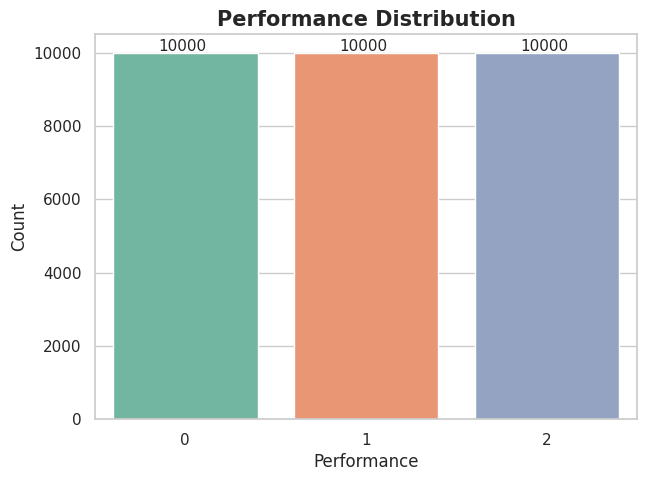

In [ ]:
plt.figure(figsize=(7,5))

ax = sns.countplot(
    data=df,
    x='Performance',
    palette='Set2'
)

for p in ax.patches:

    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x()+0.25,
         p.get_height()+40),
        fontsize=11
    )

plt.title("Performance Distribution",fontsize=15,fontweight='bold')
plt.xlabel("Performance")
plt.ylabel("Count")

plt.show()

# Label Encoding


In [ ]:
df_encoded = df.copy()

label_encoders = {}

cat_cols = df_encoded.select_dtypes(include='object').columns

for col in cat_cols:

    le = LabelEncoder()

    df_encoded[col] = le.fit_transform(df_encoded[col])

    label_encoders[col] = le

print("Encoding Completed Successfully.")

display(df_encoded.head())

Encoding Completed Successfully.


,Age,Grade,Gender,Race,SES_Quartile,ParentalEducation,SchoolType,Locale,TestScore_Math,TestScore_Reading,TestScore_Science,GPA,AttendanceRate,StudyHours,InternetAccess,Extracurricular,PartTimeJob,ParentSupport,Romantic,FreeTime,GoOut,Performance
0,17,12,0,1,1,2,1,2,68.280990,67.686488,75.293605,2.450311,0.873647,1.038520,1,0,0,1,0,2,2,0
1,17,12,0,2,4,1,1,0,100.000000,100.000000,97.782078,3.969801,1.000000,1.104243,1,1,0,1,0,1,1,2
2,15,10,0,5,4,2,1,0,88.236842,95.322476,94.413480,4.000000,0.980589,1.376388,1,0,0,0,0,3,2,2
3,16,11,1,1,4,1,1,1,85.195279,82.700191,78.184216,3.581621,0.923087,0.631498,1,0,0,0,0,4,3,2
4,14,9,1,0,3,0,0,2,65.059639,64.634338,61.016106,2.448366,0.829742,0.105131,1,1,0,0,0,3,1,0


# Encoded Dataset Info

In [ ]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                30000 non-null  int64  
 1   Grade              30000 non-null  int64  
 2   Gender             30000 non-null  int64  
 3   Race               30000 non-null  int64  
 4   SES_Quartile       30000 non-null  int64  
 5   ParentalEducation  30000 non-null  int64  
 6   SchoolType         30000 non-null  int64  
 7   Locale             30000 non-null  int64  
 8   TestScore_Math     30000 non-null  float64
 9   TestScore_Reading  30000 non-null  float64
 10  TestScore_Science  30000 non-null  float64
 11  GPA                30000 non-null  float64
 12  AttendanceRate     30000 non-null  float64
 13  StudyHours         30000 non-null  float64
 14  InternetAccess     30000 non-null  int64  
 15  Extracurricular    30000 non-null  int64  
 16  PartTimeJob        300

# Correlation

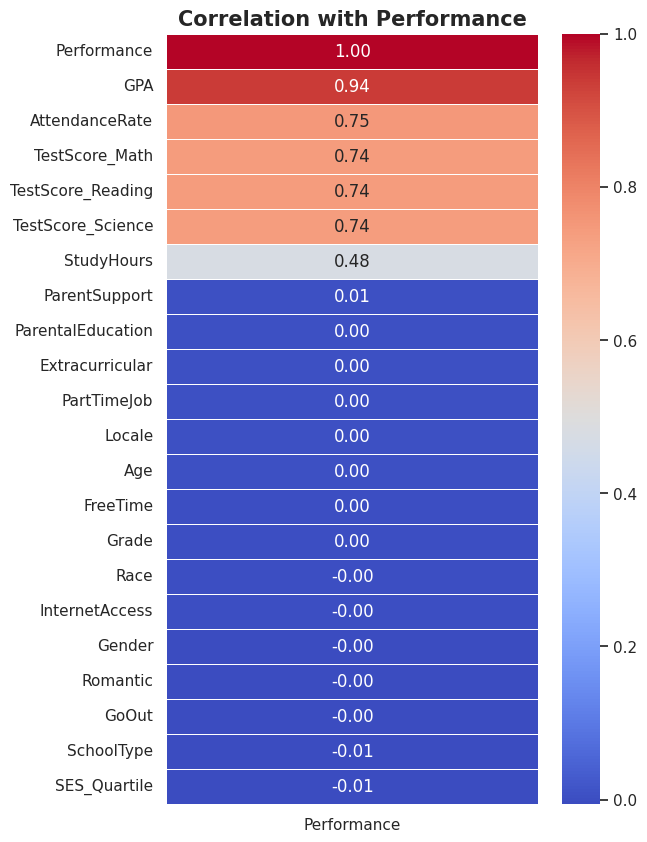

In [ ]:
corr = df_encoded.corr(numeric_only=True)

performance_corr = corr[['Performance']].sort_values(
    by='Performance',
    ascending=False
)

plt.figure(figsize=(6,10))

sns.heatmap(
    performance_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation with Performance", fontsize=15, fontweight="bold")
plt.show()

# Feature and Target


In [ ]:
X = df_encoded.drop("Performance", axis=1)
y = df_encoded["Performance"]

print("Feature Shape :", X.shape)
print("Target Shape :", y.shape)

Feature Shape : (30000, 21)
Target Shape : (30000,)


# Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples :", X_train.shape)
print("Testing Samples :", X_test.shape)

Training Samples : (24000, 21)
Testing Samples : (6000, 21)


# Random Forest Model


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=20,
    max_depth=3,
    min_samples_split=30,
    min_samples_leaf=15,
    max_features="sqrt",
    bootstrap=True,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=3, min_samples_leaf=15, min_samples_split=30,
                       n_estimators=20, random_state=42)

In [ ]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)

# Accuracy


In [ ]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest Test Accuracy : {rf_accuracy:.4f}")

Random Forest Test Accuracy : 0.9563


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.96      0.95      0.96      2000
           1       0.91      0.96      0.94      2000
           2       1.00      0.96      0.98      2000

    accuracy                           0.96      6000
   macro avg       0.96      0.96      0.96      6000
weighted avg       0.96      0.96      0.96      6000



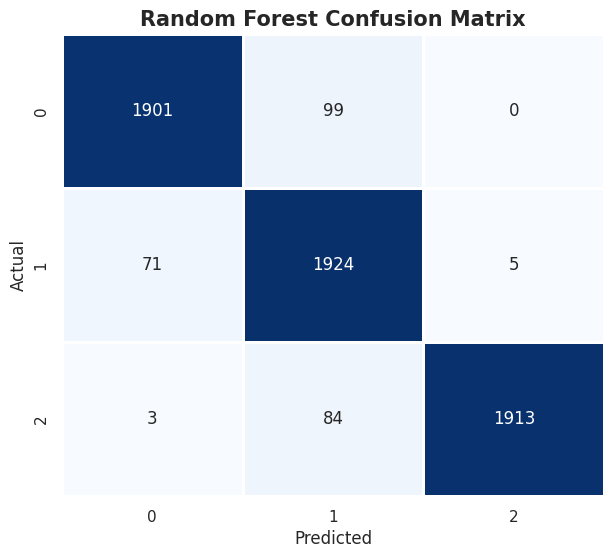

In [ ]:
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1,
    cbar=False
)

plt.title("Random Forest Confusion Matrix",
          fontsize=15,
          fontweight="bold")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

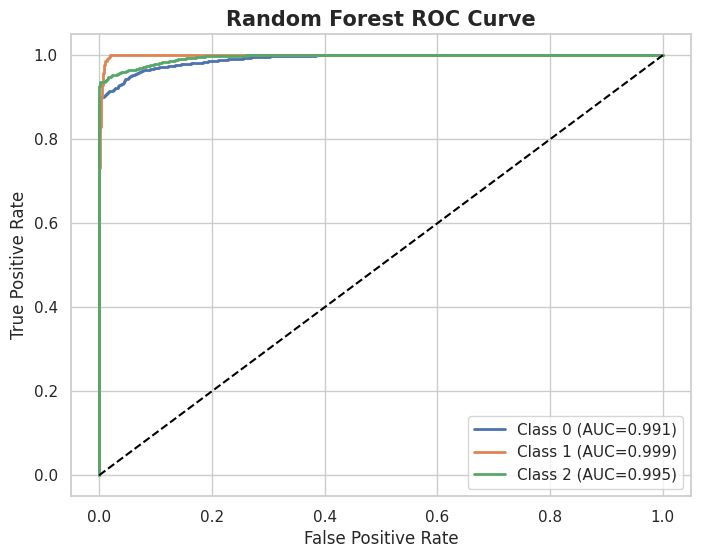

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes = np.unique(y)

y_test_bin = label_binarize(y_test, classes=classes)

plt.figure(figsize=(8,6))

for i in range(len(classes)):

    fpr, tpr, _ = roc_curve(
        y_test_bin[:,i],
        y_prob_rf[:,i]
    )

    roc_auc = auc(fpr,tpr)

    plt.plot(
        fpr,
        tpr,
        lw=2,
        label=f"Class {classes[i]} (AUC={roc_auc:.3f})"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle='--',
    color='black'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("Random Forest ROC Curve",
          fontsize=15,
          fontweight="bold")

plt.legend()

plt.show()

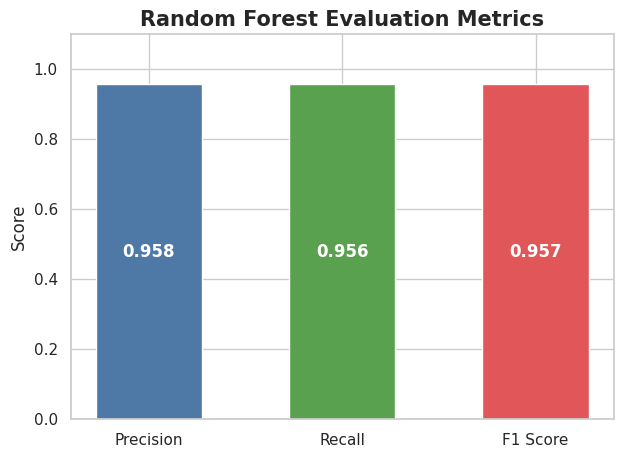

In [ ]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

precision_rf = precision_score(
    y_test,
    y_pred_rf,
    average='weighted'
)

recall_rf = recall_score(
    y_test,
    y_pred_rf,
    average='weighted'
)

f1_rf = f1_score(
    y_test,
    y_pred_rf,
    average='weighted'
)

metric_names = [
    "Precision",
    "Recall",
    "F1 Score"
]

metric_values = [
    precision_rf,
    recall_rf,
    f1_rf
]

colors = [
    "#4E79A7",
    "#59A14F",
    "#E15759"
]

plt.figure(figsize=(7,5))

bars = plt.bar(
    metric_names,
    metric_values,
    color=colors,
    width=0.55
)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height/2,
        f"{height:.3f}",
        ha='center',
        va='center',
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.ylim(0,1.1)

plt.ylabel("Score")

plt.title(
    "Random Forest Evaluation Metrics",
    fontsize=15,
    fontweight='bold'
)

plt.show()

In [ ]:
!pip install xgboost

# XGBoost

In [ ]:
from xgboost import XGBClassifier

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=8,
    max_depth=2,
    learning_rate=0.7,
    subsample=0.4,
    colsample_bytree=0.4,
    min_child_weight=30,
    gamma=10,
    reg_alpha=10,
    reg_lambda=20,
    objective='multi:softprob',
    num_class=len(np.unique(y)),
    eval_metric='mlogloss',
    random_state=42
)
xgb_model.fit(X_train, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.4, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=10,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.7, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=30, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=8, n_jobs=None, num_class=3, ...)

In [ ]:
y_pred_xgb = xgb_model.predict(X_test)

y_prob_xgb = xgb_model.predict_proba(X_test)

In [ ]:
from sklearn.metrics import accuracy_score

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

print(f"XGBoost Accuracy : {xgb_accuracy:.4f}")

XGBoost Accuracy : 0.9113


In [ ]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      2000
           1       0.87      0.86      0.87      2000
           2       0.87      0.88      0.87      2000

    accuracy                           0.91      6000
   macro avg       0.91      0.91      0.91      6000
weighted avg       0.91      0.91      0.91      6000



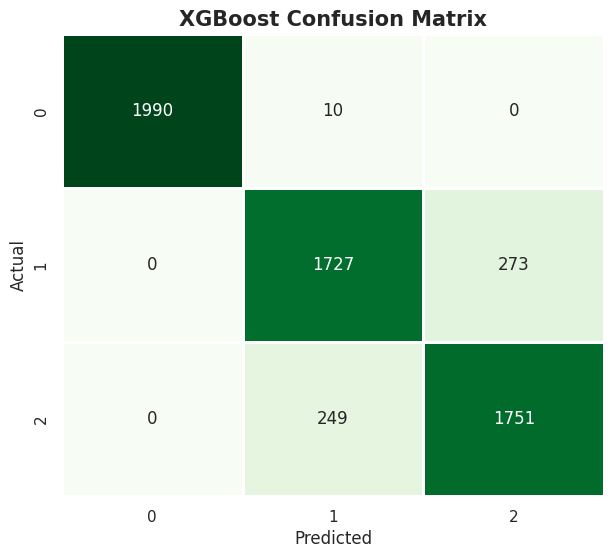

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    linewidths=1,
    cbar=False
)

plt.title("XGBoost Confusion Matrix",
          fontsize=15,
          fontweight='bold')

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

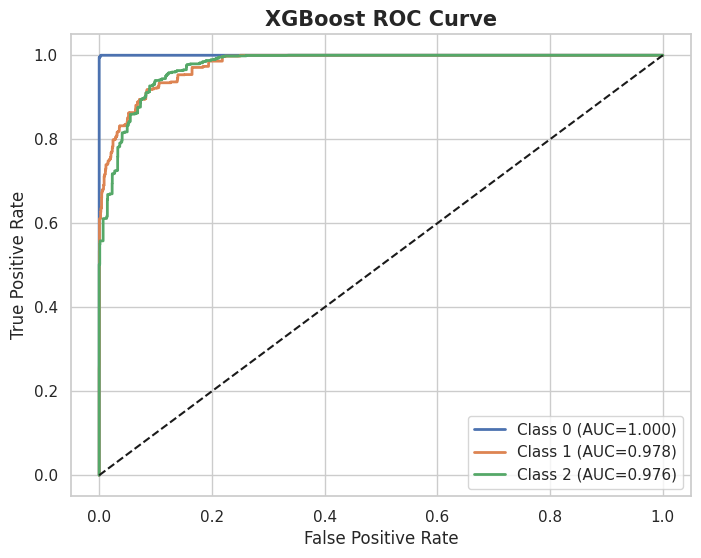

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes = np.unique(y)

y_test_bin = label_binarize(y_test, classes=classes)

plt.figure(figsize=(8,6))

for i in range(len(classes)):

    fpr, tpr, _ = roc_curve(
        y_test_bin[:,i],
        y_prob_xgb[:,i]
    )

    roc_auc = auc(fpr,tpr)

    plt.plot(
        fpr,
        tpr,
        lw=2,
        label=f"Class {classes[i]} (AUC={roc_auc:.3f})"
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("XGBoost ROC Curve",
          fontsize=15,
          fontweight='bold')

plt.legend()

plt.show()

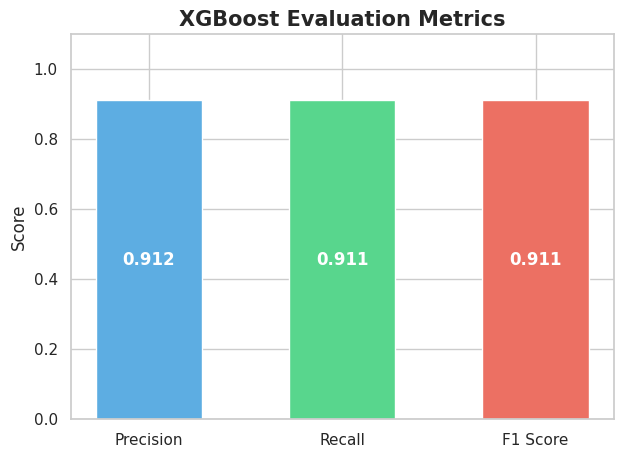

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_xgb = precision_score(
    y_test,
    y_pred_xgb,
    average='weighted'
)

recall_xgb = recall_score(
    y_test,
    y_pred_xgb,
    average='weighted'
)

f1_xgb = f1_score(
    y_test,
    y_pred_xgb,
    average='weighted'
)

metrics = [
    precision_xgb,
    recall_xgb,
    f1_xgb
]

names = [
    "Precision",
    "Recall",
    "F1 Score"
]

colors = [
    "#5DADE2",
    "#58D68D",
    "#EC7063"
]

plt.figure(figsize=(7,5))

bars = plt.bar(
    names,
    metrics,
    color=colors,
    width=0.55
)

for bar in bars:

    h = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        h/2,
        f"{h:.3f}",
        ha='center',
        va='center',
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.ylim(0,1.1)

plt.ylabel("Score")

plt.title(
    "XGBoost Evaluation Metrics",
    fontsize=15,
    fontweight='bold'
)

plt.show()

In [ ]:
model_accuracy = {}

model_accuracy["Random Forest"] = rf_accuracy
model_accuracy["XGBoost"] = xgb_accuracy



In [ ]:
print(model_accuracy)

{'Random Forest': 0.9563333333333334, 'XGBoost': 0.9113333333333333}


# CatBoostClassifier

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.4 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostClassifier

In [ ]:
cat_model = CatBoostClassifier(
    iterations=5,
    depth=1,
    learning_rate=1.0,
    l2_leaf_reg=100,
    random_strength=20,
    bagging_temperature=10,
    loss_function='MultiClass',
    random_seed=42,
    verbose=False
)

cat_model.fit(X_train, y_train)


CatBoostClassifier(bagging_temperature=10, depth=1, iterations=5, l2_leaf_reg=100, learning_rate=1.0, loss_function='MultiClass', random_seed=42, random_strength=20, verbose=False)

In [ ]:
y_pred_cat = cat_model.predict(X_test)

y_pred_cat = y_pred_cat.astype(int).flatten()

y_prob_cat = cat_model.predict_proba(X_test)

In [ ]:
cat_accuracy = accuracy_score(
    y_test,
    y_pred_cat
)

print(f"CatBoost Accuracy : {cat_accuracy:.4f}")

CatBoost Accuracy : 0.9852


In [ ]:
print(classification_report(
    y_test,
    y_pred_cat
))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00      2000
           1       0.97      0.99      0.98      2000
           2       1.00      0.96      0.98      2000

    accuracy                           0.99      6000
   macro avg       0.99      0.99      0.99      6000
weighted avg       0.99      0.99      0.99      6000



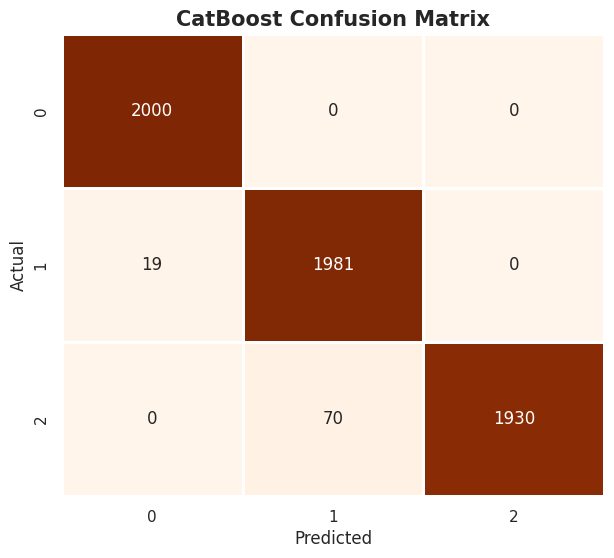

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred_cat
)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    linewidths=1,
    cbar=False
)

plt.title(
    "CatBoost Confusion Matrix",
    fontsize=15,
    fontweight='bold'
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

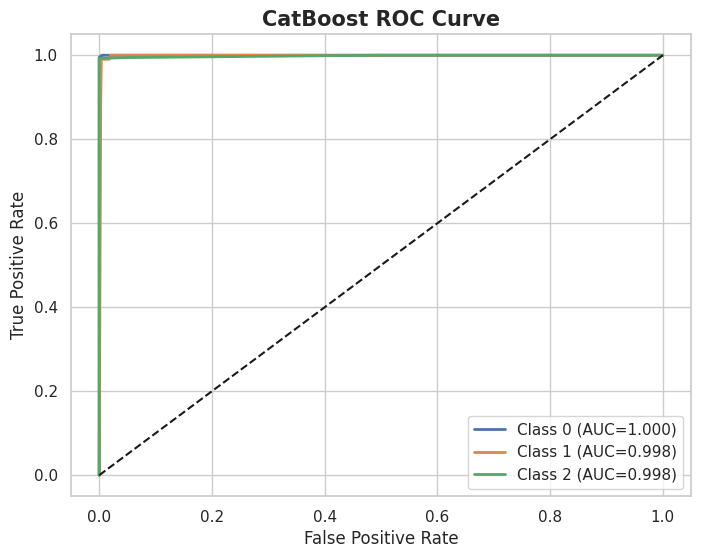

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes = np.unique(y)

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

plt.figure(figsize=(8,6))

for i in range(len(classes)):

    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_prob_cat[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        lw=2,
        label=f"Class {classes[i]} (AUC={roc_auc:.3f})"
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "CatBoost ROC Curve",
    fontsize=15,
    fontweight='bold'
)

plt.legend()

plt.show()

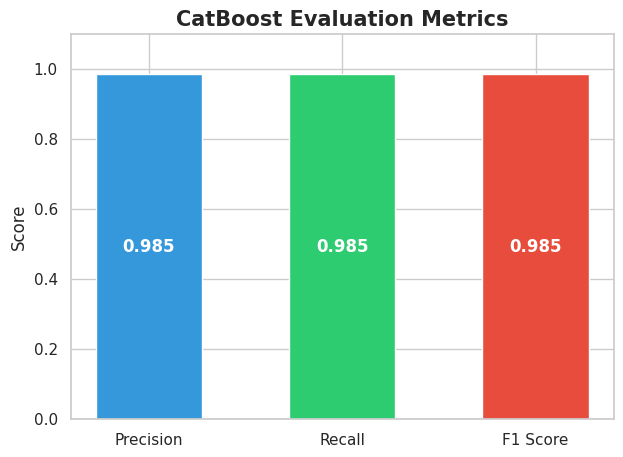

In [ ]:
precision_cat = precision_score(
    y_test,
    y_pred_cat,
    average='weighted'
)

recall_cat = recall_score(
    y_test,
    y_pred_cat,
    average='weighted'
)

f1_cat = f1_score(
    y_test,
    y_pred_cat,
    average='weighted'
)

metric_names = [
    "Precision",
    "Recall",
    "F1 Score"
]

metric_values = [
    precision_cat,
    recall_cat,
    f1_cat
]

colors = [
    "#3498DB",
    "#2ECC71",
    "#E74C3C"
]

plt.figure(figsize=(7,5))

bars = plt.bar(
    metric_names,
    metric_values,
    color=colors,
    width=0.55
)

for bar in bars:

    h = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        h/2,
        f"{h:.3f}",
        ha='center',
        va='center',
        fontsize=12,
        color='white',
        fontweight='bold'
    )

plt.ylim(0,1.1)

plt.ylabel("Score")

plt.title(
    "CatBoost Evaluation Metrics",
    fontsize=15,
    fontweight='bold'
)

plt.show()

In [ ]:
model_accuracy["CatBoost"] = cat_accuracy

print(model_accuracy)

{'Random Forest': 0.9563333333333334, 'XGBoost': 0.9113333333333333, 'CatBoost': 0.9851666666666666}


# MLP Classifier (Multi-Layer Perceptron)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.neural_network import MLPClassifier

In [ ]:
mlp_model = MLPClassifier(

    hidden_layer_sizes=(64,32),

    activation='relu',

    solver='adam',

    alpha=0.001,

    learning_rate_init=0.001,

    max_iter=300,

    random_state=42

)

mlp_model.fit(X_train_scaled, y_train)



MLPClassifier(alpha=0.001, hidden_layer_sizes=(64, 32), max_iter=300,
              random_state=42)

In [ ]:
y_pred_mlp = mlp_model.predict(X_test_scaled)

y_prob_mlp = mlp_model.predict_proba(X_test_scaled)

In [ ]:
mlp_accuracy = accuracy_score(
    y_test,
    y_pred_mlp
)

print(f"MLP Accuracy : {mlp_accuracy:.4f}")

MLP Accuracy : 0.9827


In [ ]:
print(classification_report(
    y_test,
    y_pred_mlp
))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2000
           1       0.98      0.97      0.97      2000
           2       0.99      0.99      0.99      2000

    accuracy                           0.98      6000
   macro avg       0.98      0.98      0.98      6000
weighted avg       0.98      0.98      0.98      6000



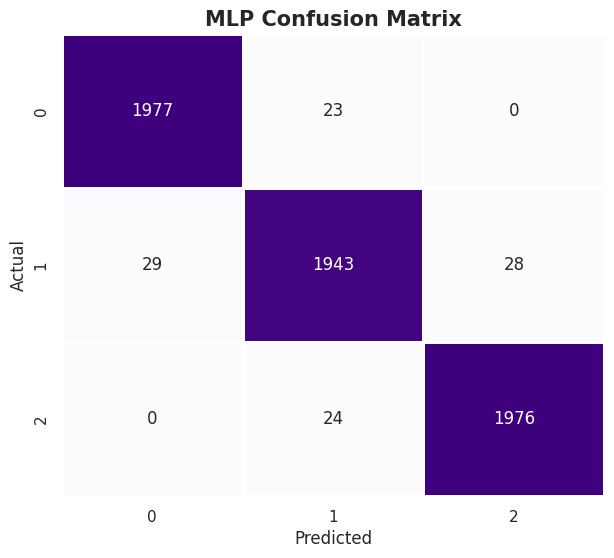

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred_mlp
)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Purples',
    linewidths=1,
    cbar=False
)

plt.title(
    "MLP Confusion Matrix",
    fontsize=15,
    fontweight='bold'
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

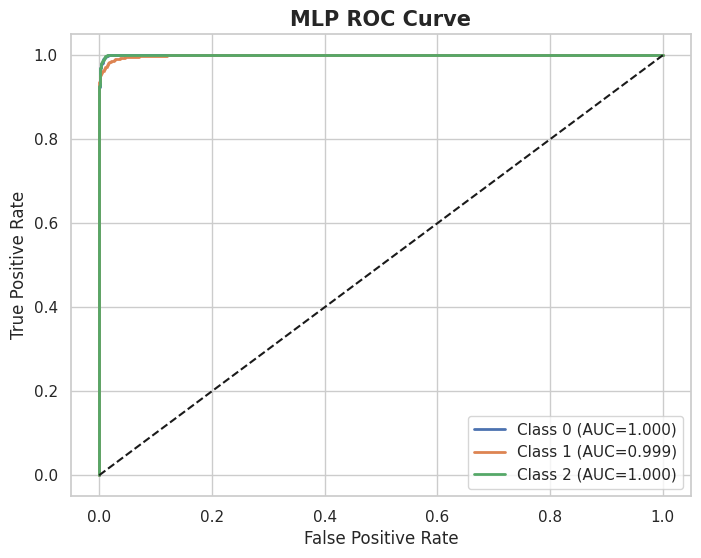

In [ ]:

classes = np.unique(y)

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

plt.figure(figsize=(8,6))

for i in range(len(classes)):

    fpr, tpr, _ = roc_curve(
        y_test_bin[:,i],
        y_prob_mlp[:,i]
    )

    roc_auc = auc(fpr,tpr)

    plt.plot(
        fpr,
        tpr,
        lw=2,
        label=f"Class {classes[i]} (AUC={roc_auc:.3f})"
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title(
    "MLP ROC Curve",
    fontsize=15,
    fontweight='bold'
)

plt.legend()

plt.show()

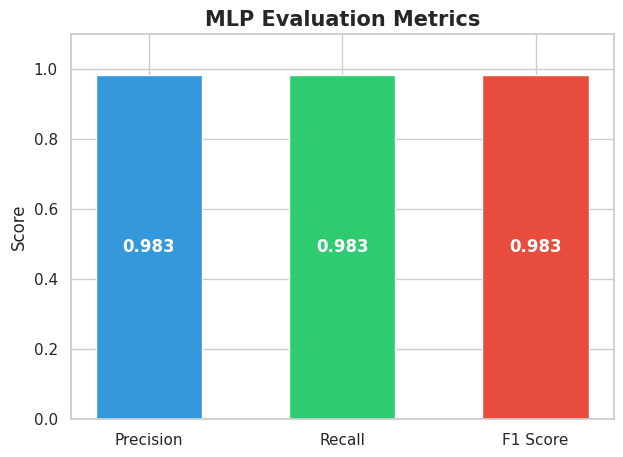

In [ ]:
precision_mlp = precision_score(
    y_test,
    y_pred_mlp,
    average='weighted'
)

recall_mlp = recall_score(
    y_test,
    y_pred_mlp,
    average='weighted'
)

f1_mlp = f1_score(
    y_test,
    y_pred_mlp,
    average='weighted'
)

metric_names = [
    "Precision",
    "Recall",
    "F1 Score"
]

metric_values = [
    precision_mlp,
    recall_mlp,
    f1_mlp
]

colors = [
    "#3498DB",
    "#2ECC71",
    "#E74C3C"
]

plt.figure(figsize=(7,5))

bars = plt.bar(
    metric_names,
    metric_values,
    color=colors,
    width=0.55
)

for bar in bars:

    h = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        h/2,
        f"{h:.3f}",
        ha='center',
        va='center',
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.ylim(0,1.1)

plt.ylabel("Score")

plt.title(
    "MLP Evaluation Metrics",
    fontsize=15,
    fontweight='bold'
)

plt.show()

In [ ]:
model_accuracy["MLP"] = mlp_accuracy

print(model_accuracy)

{'Random Forest': 0.9563333333333334, 'XGBoost': 0.9113333333333333, 'CatBoost': 0.9851666666666666, 'MLP': 0.9826666666666667}


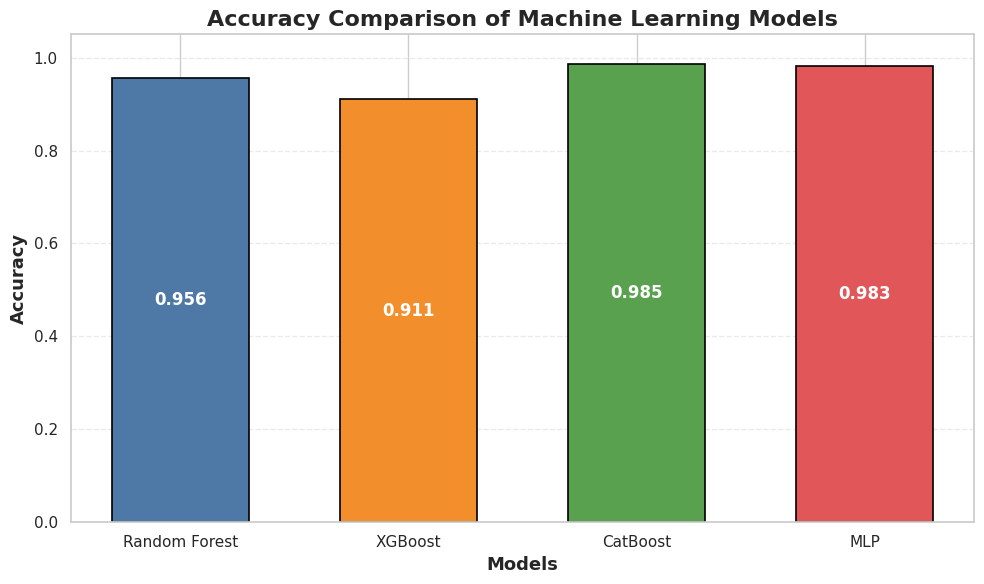

In [ ]:
models = [
    "Random Forest",
    "XGBoost",
    "CatBoost",
    "MLP"
]

accuracies = [
    rf_accuracy,
    xgb_accuracy,
    cat_accuracy,
    mlp_accuracy
]

colors = [
    "#4E79A7",   # Blue
    "#F28E2B",   # Orange
    "#59A14F",   # Green
    "#E15759"    # Red
]

plt.figure(figsize=(10,6))

bars = plt.bar(
    models,
    accuracies,
    color=colors,
    width=0.6,
    edgecolor="black",
    linewidth=1.2
)

# Value in the middle of each bar
for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height/2,
        f"{height:.3f}",
        ha='center',
        va='center',
        fontsize=12,
        fontweight='bold',
        color='white'
    )

plt.title(
    "Accuracy Comparison of Machine Learning Models",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel(
    "Models",
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    "Accuracy",
    fontsize=13,
    fontweight='bold'
)

plt.ylim(0, 1.05)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.tight_layout()

plt.show()

# 5-Fold Stratified Cross-Validation (With best model)


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    cat_model,
    X_train,
    y_train,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1
)

print("5-Fold Cross-Validation Accuracy:")
for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i}: {score*100:.2f}%")

print(f"\nMean CV Accuracy: {cv_scores.mean()*100:.2f}%")
print(f"Standard Deviation: {cv_scores.std()*100:.2f}%")

5-Fold Cross-Validation Accuracy:
Fold 1: 99.85%
Fold 2: 99.52%
Fold 3: 99.58%
Fold 4: 99.77%
Fold 5: 99.73%

Mean CV Accuracy: 99.69%
Standard Deviation: 0.12%


# Ordinal Wrapper

In [ ]:



# Model A: Performance > Low?
y_train_A = (y_train > 0).astype(int)
y_test_A = (y_test > 0).astype(int)

# Model B: Performance > Average?
y_train_B = (y_train > 1).astype(int)
y_test_B = (y_test > 1).astype(int)




model_A = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="Accuracy",
    random_seed=42,
    verbose=0
)

model_B = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="Accuracy",
    random_seed=42,
    verbose=0
)




model_A.fit(X_train, y_train_A)
model_B.fit(X_train, y_train_B)




# P(Performance > Low) = P(Average or High)
prob_A = model_A.predict_proba(X_test)[:, 1]

# P(Performance > Average) = P(High)
prob_B = model_B.predict_proba(X_test)[:, 1]




# P(Low)
prob_low = 1 - prob_A

# P(Average)
prob_average = prob_A - prob_B

# P(High)
prob_high = prob_B



ordinal_probs = np.column_stack([
    prob_low,
    prob_average,
    prob_high
])




y_pred_ordinal = np.argmax(ordinal_probs, axis=1)



accuracy = accuracy_score(y_test, y_pred_ordinal)





label_map = {
    0: "Low",
    1: "Average",
    2: "High"
}

probability_df = pd.DataFrame({
    "Actual": y_test.values[:10],
    "P(Low)": prob_low[:10],
    "P(Average)": prob_average[:10],
    "P(High)": prob_high[:10],
    "Predicted": y_pred_ordinal[:10]
})

probability_df["Actual"] = probability_df["Actual"].map(label_map)
probability_df["Predicted"] = probability_df["Predicted"].map(label_map)

probability_df[["P(Low)", "P(Average)", "P(High)"]] = (
    probability_df[["P(Low)", "P(Average)", "P(High)"]].round(4)
)

print("\nFirst 10 Predictions:")
display(probability_df)


First 10 Predictions:


,Actual,P(Low),P(Average),P(High),Predicted
0,Low,0.9999,0.0001,0.0000,Low
1,High,0.0000,0.0001,0.9999,High
2,High,0.0000,0.0001,0.9999,High
3,Low,0.9999,0.0001,0.0000,Low
4,Average,0.0001,0.9999,0.0000,Average
5,Low,0.9999,0.0001,0.0000,Low
6,Average,0.0000,0.9999,0.0001,Average
7,Average,0.0001,0.9999,0.0000,Average
8,Low,0.9997,0.0003,0.0000,Low
9,High,0.0000,0.0000,0.9999,High


# QWK / MAE / Severe-Error Rate

In [ ]:


from sklearn.metrics import cohen_kappa_score, mean_absolute_error

# Quadratic Weighted Kappa
qwk = cohen_kappa_score(
    y_test,
    y_pred_ordinal,
    weights="quadratic"
)

# Mean Absolute Error
mae = mean_absolute_error(
    y_test,
    y_pred_ordinal
)

# Severe Error Rate
# Error of 2 levels: Low ↔ High
severe_error = (
    np.abs(np.array(y_test) - np.array(y_pred_ordinal)) == 2
).mean()

print("ORDINAL PERFORMANCE METRICS")

print(f"QWK (Quadratic Weighted Kappa): {qwk:.4f}")
print(f"MAE (Mean Absolute Error):       {mae:.4f}")
print(f"Severe-Error Rate:               {severe_error * 100:.2f}%")

ORDINAL PERFORMANCE METRICS
QWK (Quadratic Weighted Kappa): 0.9965
MAE (Mean Absolute Error):       0.0047
Severe-Error Rate:               0.00%


# STANDARD vs ORDINAL COMPARISON

In [ ]:


import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    mean_absolute_error
)

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.neural_network import MLPClassifier


# 1. Function: Frank & Hall Ordinal Wrapper

def frank_hall_ordinal(
    model_class,
    model_params,
    X_train,
    y_train,
    X_test
):

    # Model A: Performance > Low?
    # Low = 0
    # Average/High = 1

    y_train_A = (np.asarray(y_train) > 0).astype(int)


    # Model B: Performance > Average?
    # Low/Average = 0
    # High = 1

    y_train_B = (np.asarray(y_train) > 1).astype(int)


    # Train Model A


    model_A = model_class(**model_params)
    model_A.fit(X_train, y_train_A)


    # Train Model B

    model_B = model_class(**model_params)
    model_B.fit(X_train, y_train_B)



    # Get Probabilities

    # P(Average or High)
    prob_A = model_A.predict_proba(X_test)[:, 1]

    # P(High)
    prob_B = model_B.predict_proba(X_test)[:, 1]


    # Calculate Class Probabilities

    # P(Low)
    prob_low = 1 - prob_A

    # P(Average)
    prob_average = prob_A - prob_B

    # P(High)
    prob_high = prob_B


    # Prevent negative probabilities

    prob_average = np.maximum(prob_average, 0)


    # Combine Probabilities

    ordinal_probs = np.column_stack([
        prob_low,
        prob_average,
        prob_high
    ])


    # Normalize probabilities

    row_sum = ordinal_probs.sum(axis=1, keepdims=True)

    ordinal_probs = ordinal_probs / np.where(
        row_sum == 0,
        1,
        row_sum
    )


    # Final Prediction

    y_pred_ordinal = np.argmax(
        ordinal_probs,
        axis=1
    )


    return y_pred_ordinal, ordinal_probs


# 2. Model Parameters

rf_params = {
    "n_estimators": 200,
    "random_state": 42,
    "n_jobs": -1
}


xgb_params = {
    "n_estimators": 300,
    "max_depth": 6,
    "learning_rate": 0.05,
    "random_state": 42,
    "n_jobs": -1,
    "eval_metric": "mlogloss"
}


cat_params = {
    "iterations": 500,
    "depth": 6,
    "learning_rate": 0.05,
    "random_seed": 42,
    "verbose": 0
}


mlp_params = {
    "hidden_layer_sizes": (100, 50),
    "max_iter": 500,
    "random_state": 42
}


# 3. Create Ordinal Versions of All Four Models

# RF Ordinal

y_pred_rf_ordinal, rf_ordinal_probs = frank_hall_ordinal(
    RandomForestClassifier,
    rf_params,
    X_train,
    y_train,
    X_test
)


# XGBoost Ordinal

y_pred_xgb_ordinal, xgb_ordinal_probs = frank_hall_ordinal(
    XGBClassifier,
    xgb_params,
    X_train,
    y_train,
    X_test
)


# CatBoost Ordinal

y_pred_cat_ordinal, cat_ordinal_probs = frank_hall_ordinal(
    CatBoostClassifier,
    cat_params,
    X_train,
    y_train,
    X_test
)


#  MLP Ordinal

y_pred_mlp_ordinal, mlp_ordinal_probs = frank_hall_ordinal(
    MLPClassifier,
    mlp_params,
    X_train,
    y_train,
    X_test
)



# 4. Calculate Evaluation Metrics

def calculate_metrics(y_true, y_pred):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    qwk = cohen_kappa_score(
        y_true,
        y_pred,
        weights="quadratic"
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    severe_error = (
        np.abs(y_true - y_pred) == 2
    ).mean()

    return accuracy, qwk, mae, severe_error


# 5. Standard Predictions

standard_predictions = {

    "RF (Standard)": y_pred_rf,

    "XGB (Standard)": y_pred_xgb,

    "CatBoost (Standard)": y_pred_cat,

    "MLP (Standard)": y_pred_mlp
}


# 6. Ordinal Predictions

ordinal_predictions = {

    "RF (Ordinal)": y_pred_rf_ordinal,

    "XGB (Ordinal)": y_pred_xgb_ordinal,

    "CatBoost (Ordinal)": y_pred_cat_ordinal,

    "MLP (Ordinal)": y_pred_mlp_ordinal
}


# 7. Create Comparison Results

results = []


all_predictions = {
    **standard_predictions,
    **ordinal_predictions
}


for model_name, predictions in all_predictions.items():

    accuracy, qwk, mae, severe = calculate_metrics(
        y_test,
        predictions
    )

    results.append({

        "Model": model_name,

        "Accuracy (%)": accuracy * 100,

        "QWK": qwk,

        "MAE": mae,

        "Severe-Error (%)": severe * 100

    })


# 8. Comparison Table

comparison_df = pd.DataFrame(results)


comparison_df["Accuracy (%)"] = (
    comparison_df["Accuracy (%)"]
    .round(2)
)

comparison_df["QWK"] = (
    comparison_df["QWK"]
    .round(4)
)

comparison_df["MAE"] = (
    comparison_df["MAE"]
    .round(4)
)

comparison_df["Severe-Error (%)"] = (
    comparison_df["Severe-Error (%)"]
    .round(2)
)




In [ ]:
# Display Final Comparison

print("STANDARD vs ORDINAL MODEL COMPARISON")
display(comparison_df)

STANDARD vs ORDINAL MODEL COMPARISON


,Model,Accuracy (%),QWK,MAE,Severe-Error (%)
0,RF (Standard),95.63,0.9657,0.0442,0.05
1,XGB (Standard),91.13,0.9336,0.0887,0.00
2,CatBoost (Standard),98.52,0.9888,0.0148,0.00
3,MLP (Standard),98.27,0.9870,0.0173,0.00
4,RF (Ordinal),99.98,0.9999,0.0002,0.00
5,XGB (Ordinal),99.50,0.9962,0.0050,0.00
6,CatBoost (Ordinal),99.53,0.9965,0.0047,0.00
7,MLP (Ordinal),96.93,0.9775,0.0307,0.00


# Stacking Ensemble (RF + XGBoost + CatBoost)

In [ ]:


from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns


# 1. Define Stacking Ensemble

stack = StackingClassifier(
    estimators=[
        ("rf", rf_model),
        ("xgb", xgb_model),
        ("cat", cat_model)
    ],
    final_estimator=LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    cv=5,
    n_jobs=-1
)


# 2. Train Stacking Ensemble

stack.fit(
    X_train,
    y_train
)


# 3. Prediction

y_pred_stack = stack.predict(X_test)




STACKING ENSEMBLE RESULTS (RF + XGBoost + CatBoost)

Accuracy: 99.33%

Classification Report:
              precision    recall  f1-score   support

         Low     0.9980    1.0000    0.9990      2000
     Average     0.9823    0.9980    0.9901      2000
        High     1.0000    0.9820    0.9909      2000

    accuracy                         0.9933      6000
   macro avg     0.9934    0.9933    0.9933      6000
weighted avg     0.9934    0.9933    0.9933      6000



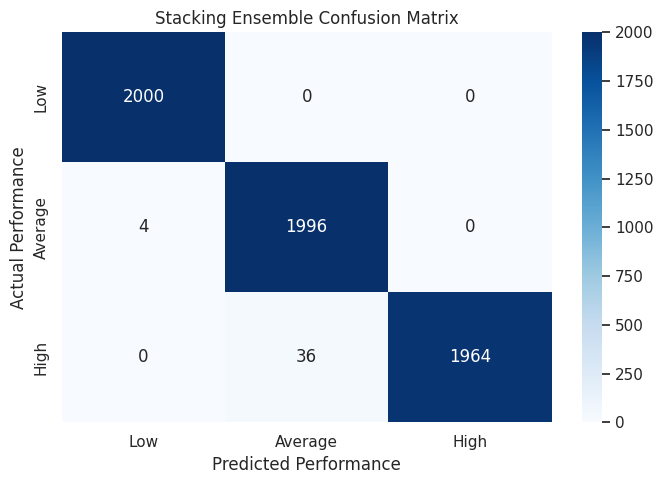

In [ ]:
# 4. Accuracy

stack_accuracy = accuracy_score(
    y_test,
    y_pred_stack
)

print("STACKING ENSEMBLE RESULTS (RF + XGBoost + CatBoost)")

print(f"\nAccuracy: {stack_accuracy * 100:.2f}%")


# 5. Classification Report

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_stack,
        target_names=["Low", "Average", "High"],
        digits=4
    )
)


# 6. Confusion Matrix

cm_stack = confusion_matrix(
    y_test,
    y_pred_stack
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_stack,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Average", "High"],
    yticklabels=["Low", "Average", "High"]
)

plt.xlabel("Predicted Performance")
plt.ylabel("Actual Performance")
plt.title("Stacking Ensemble Confusion Matrix")

plt.tight_layout()
plt.show()

# Wrong-Classified Pattern Analysis

In [ ]:


import pandas as pd
import numpy as np

# Make a copy of X_test
wrong = X_test.copy()

# Add actual and predicted performance
wrong["Actual"] = np.array(y_test)
wrong["Predicted"] = np.array(y_pred_stack)

# Keep only incorrectly classified samples
wrong = wrong[wrong["Actual"] != wrong["Predicted"]].copy()

print("WRONG-CLASSIFIED PATTERN ANALYSIS")

print(f"\nTotal Test Samples      : {len(X_test)}")
print(f"Wrongly Classified     : {len(wrong)}")
print(f"Error Rate             : {len(wrong) / len(X_test) * 100:.2f}%")



WRONG-CLASSIFIED PATTERN ANALYSIS

Total Test Samples      : 6000
Wrongly Classified     : 40
Error Rate             : 0.67%


In [ ]:
# 1. Wrong Prediction Summary

print("\nWrong Prediction Summary:")
display(
    wrong[["Actual", "Predicted"]]
    .value_counts()
    .reset_index(name="Count")
)




Wrong Prediction Summary:


,Actual,Predicted,Count
0,2,1,36
1,1,0,4


In [ ]:

# 2. Compare Numerical Features

print("\nNumerical Feature Comparison:")
display(
    pd.DataFrame({
        "Overall Mean": X_test.select_dtypes(
            include=np.number
        ).mean(),

        "Wrong Prediction Mean": wrong[
            X_test.select_dtypes(include=np.number).columns
        ].mean()
    }).round(3)
)





Numerical Feature Comparison:


,Overall Mean,Wrong Prediction Mean
Age,16.013,15.975
Grade,10.808,10.750
Gender,0.484,0.475
Race,3.193,3.450
SES_Quartile,2.493,2.925
ParentalEducation,1.731,1.950
SchoolType,0.853,0.775
Locale,1.268,1.000
TestScore_Math,74.762,75.995
TestScore_Reading,74.970,76.755


In [ ]:
# 3. Overall Test Data Description

print("\nOverall Test Data:")
display(
    X_test.describe().round(3)
)





Overall Test Data:


,Age,Grade,Gender,Race,SES_Quartile,ParentalEducation,SchoolType,Locale,TestScore_Math,TestScore_Reading,TestScore_Science,GPA,AttendanceRate,StudyHours,InternetAccess,Extracurricular,PartTimeJob,ParentSupport,Romantic,FreeTime,GoOut
count,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000,6000.000
mean,16.013,10.808,0.484,3.193,2.493,1.731,0.853,1.268,74.762,74.970,74.979,2.988,0.899,0.995,0.854,0.545,0.178,0.417,0.209,2.996,2.053
std,1.416,1.163,0.500,1.777,1.116,1.079,0.354,1.018,11.676,11.649,11.809,0.627,0.057,0.368,0.353,0.498,0.383,0.493,0.407,1.010,0.905
min,14.000,9.000,0.000,0.000,1.000,0.000,0.000,0.000,34.638,36.354,30.761,1.352,0.713,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000
25%,15.000,10.000,0.000,2.000,1.000,1.000,1.000,0.000,66.212,66.486,66.343,2.421,0.856,0.738,1.000,0.000,0.000,0.000,0.000,2.000,1.000
50%,16.000,11.000,0.000,3.000,2.000,2.000,1.000,1.000,74.630,74.939,75.033,2.987,0.899,0.998,1.000,1.000,0.000,0.000,0.000,3.000,2.000
75%,17.000,12.000,1.000,5.000,3.000,3.000,1.000,2.000,83.428,83.664,83.634,3.573,0.942,1.240,1.000,1.000,0.000,1.000,0.000,4.000,3.000
max,18.000,12.000,1.000,5.000,4.000,3.000,1.000,3.000,100.000,100.000,100.000,4.000,1.000,2.356,1.000,1.000,1.000,1.000,1.000,5.000,5.000


In [ ]:
# 4. Wrong Prediction Data Description

print("\nWrong Prediction Data:")
display(
    wrong.drop(
        columns=["Actual", "Predicted"]
    ).describe().round(3)
)





Wrong Prediction Data:


,Age,Grade,Gender,Race,SES_Quartile,ParentalEducation,SchoolType,Locale,TestScore_Math,TestScore_Reading,TestScore_Science,GPA,AttendanceRate,StudyHours,InternetAccess,Extracurricular,PartTimeJob,ParentSupport,Romantic,FreeTime,GoOut
count,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.00,40.000
mean,15.975,10.750,0.475,3.450,2.925,1.950,0.775,1.000,75.995,76.755,78.341,3.404,0.904,0.969,0.875,0.600,0.075,0.500,0.250,2.75,1.775
std,1.423,1.127,0.506,1.825,1.185,1.061,0.423,0.906,8.881,9.675,6.656,0.304,0.040,0.390,0.335,0.496,0.267,0.506,0.439,1.08,0.768
min,14.000,9.000,0.000,0.000,1.000,0.000,0.000,0.000,56.444,52.958,57.145,2.501,0.813,0.253,0.000,0.000,0.000,0.000,0.000,1.00,1.000
25%,15.000,10.000,0.000,2.000,2.000,1.000,1.000,0.000,73.024,72.246,74.068,3.501,0.888,0.700,1.000,0.000,0.000,0.000,0.000,2.00,1.000
50%,16.000,11.000,0.000,5.000,3.000,2.000,1.000,1.000,76.269,78.879,79.614,3.504,0.905,0.960,1.000,1.000,0.000,0.500,0.000,3.00,2.000
75%,17.000,12.000,1.000,5.000,4.000,3.000,1.000,2.000,81.672,82.141,81.635,3.506,0.928,1.220,1.000,1.000,0.000,1.000,0.250,3.25,2.000
max,18.000,12.000,1.000,5.000,4.000,3.000,1.000,3.000,91.709,95.269,92.040,3.508,0.989,1.882,1.000,1.000,1.000,1.000,1.000,5.00,3.000


In [ ]:
# 5. Actual → Predicted Error Pattern

error_pattern = pd.crosstab(
    wrong["Actual"],
    wrong["Predicted"]
)

error_pattern.index = [
    "Low" if i == 0 else
    "Average" if i == 1 else
    "High"
    for i in error_pattern.index
]

error_pattern.columns = [
    "Low" if i == 0 else
    "Average" if i == 1 else
    "High"
    for i in error_pattern.columns
]

print("\nActual → Predicted Error Pattern:")
display(error_pattern)


Actual → Predicted Error Pattern:


,Low,Average
Average,4,0
High,0,36


# Standard vs Ordinal Severe-Error Comparison


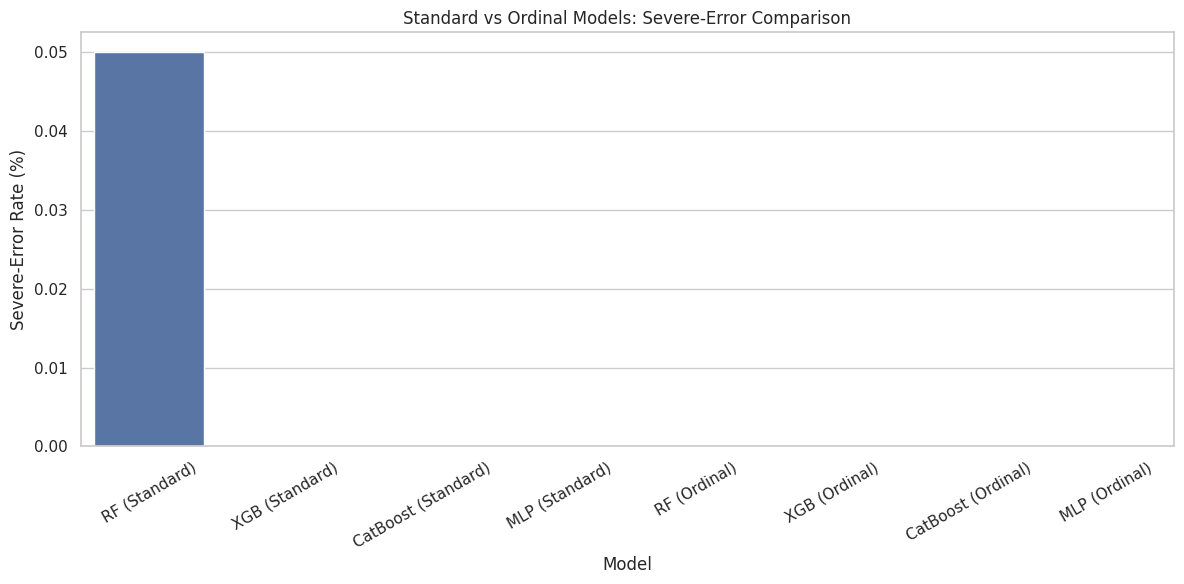

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Extract Severe-Error Results

severe_df = comparison_df[
    ["Model", "Severe-Error (%)"]
].copy()

# Plot

plt.figure(figsize=(12, 6))

sns.barplot(
    data=severe_df,
    x="Model",
    y="Severe-Error (%)"
)

plt.xlabel("Model")
plt.ylabel("Severe-Error Rate (%)")
plt.title("Standard vs Ordinal Models: Severe-Error Comparison")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
# SHAP Importance - CatBoost

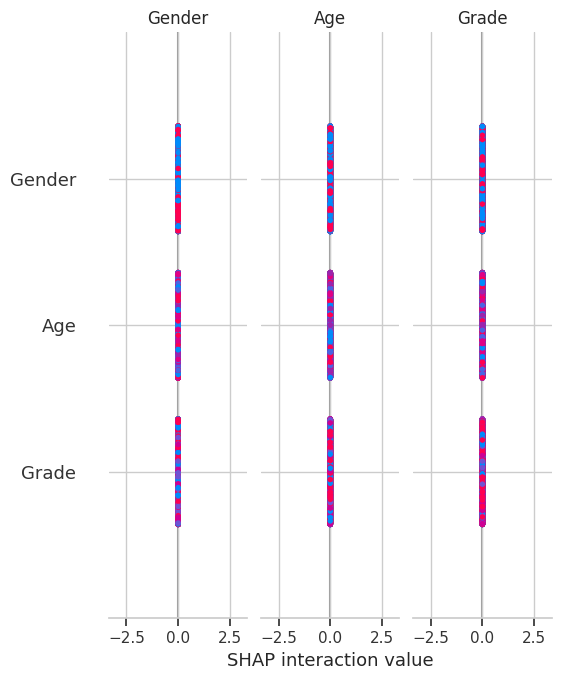

In [ ]:

import shap
import matplotlib.pyplot as plt

# Create SHAP explainer
explainer = shap.TreeExplainer(cat_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test)

# SHAP Summary Plot
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X_test.columns
)

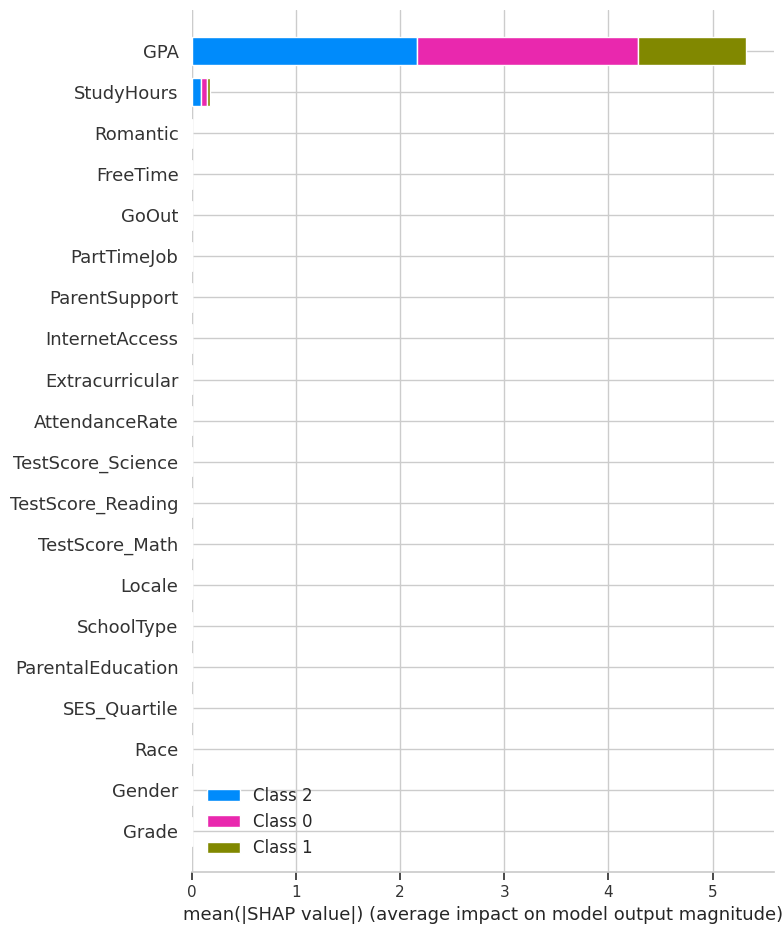

In [ ]:
# SHAP Feature Importance
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X_test.columns,
    plot_type="bar"
)

# Fairness / Subgroup Analysis

In [ ]:
from catboost import CatBoostRegressor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

confounder_cols = [
    "SES_Quartile",
    "ParentalEducation",
    "SchoolType",
    "Age",
    "Grade"
]

cat_cols = [
    "ParentalEducation",
    "SchoolType"
]

X = df[confounder_cols].copy()
T = df["AttendanceRate"]
Y = df["GPA"]

for col in cat_cols:
    X[col] = X[col].astype(str)

model = CatBoostRegressor(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    verbose=0
)

model.fit(
    X,
    Y,
    cat_features=cat_cols
)

base_prediction = model.predict(X)

effect_df = df.copy()
effect_df["Predicted_GPA"] = base_prediction

effect_df["Attendance_10pct"] = (
    effect_df["AttendanceRate"] + 0.10
).clip(upper=1.0)

X_increased = X.copy()

X_increased["AttendanceRate"] = (
    effect_df["Attendance_10pct"]
)

model_with_attendance = CatBoostRegressor(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    verbose=0
)

X_with_attendance = X.copy()
X_with_attendance["AttendanceRate"] = T

model_with_attendance.fit(
    X_with_attendance,
    Y,
    cat_features=cat_cols
)

X_counterfactual = X.copy()
X_counterfactual["AttendanceRate"] = effect_df[
    "Attendance_10pct"
]

pred_current = model_with_attendance.predict(
    X_with_attendance
)

pred_increased = model_with_attendance.predict(
    X_counterfactual
)

effect_df["Attendance_Effect_10pct"] = (
    pred_increased - pred_current
)

def subgroup_effect(data, group_column):

    return (
        data.groupby(group_column)
        ["Attendance_Effect_10pct"]
        .agg(
            Mean_Effect="mean",
            Std_Effect="std",
            Sample_Size="count"
        )
        .reset_index()
    )

gender_effect = subgroup_effect(
    effect_df,
    "Gender"
)

race_effect = subgroup_effect(
    effect_df,
    "Race"
)

ses_effect = subgroup_effect(
    effect_df,
    "SES_Quartile"
)



In [ ]:
print("AttendanceRate Effect by Gender")
display(gender_effect.round(4))



AttendanceRate Effect by Gender


,Gender,Mean_Effect,Std_Effect,Sample_Size
0,Female,0.6375,0.3524,15316
1,Male,0.6343,0.3563,14684


In [ ]:
print("\nAttendanceRate Effect by Race")
display(race_effect.round(4))




AttendanceRate Effect by Race


,Race,Mean_Effect,Std_Effect,Sample_Size
0,Asian,0.6309,0.3554,1498
1,Black,0.6288,0.3572,4471
2,Hispanic,0.6372,0.3548,8630
3,Other,0.6445,0.3503,567
4,Two-or-more,0.6282,0.3479,1556
5,White,0.6386,0.3539,13278


In [ ]:
print("\nAttendanceRate Effect by SES")
display(ses_effect.round(4))




AttendanceRate Effect by SES


,SES_Quartile,Mean_Effect,Std_Effect,Sample_Size
0,1,0.6426,0.3551,7488
1,2,0.6349,0.3556,7429
2,3,0.6333,0.3532,7581
3,4,0.6329,0.3535,7502


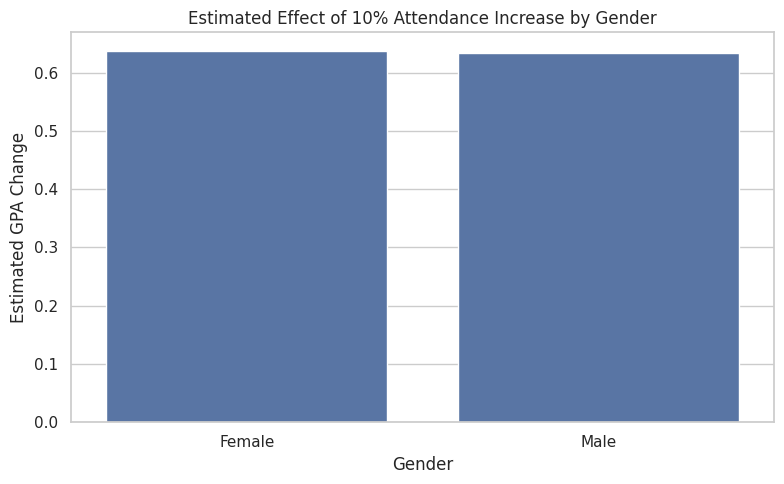

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_effect,
    x="Gender",
    y="Mean_Effect"
)

plt.xlabel("Gender")
plt.ylabel("Estimated GPA Change")
plt.title(
    "Estimated Effect of 10% Attendance Increase by Gender"
)

plt.tight_layout()
plt.show()



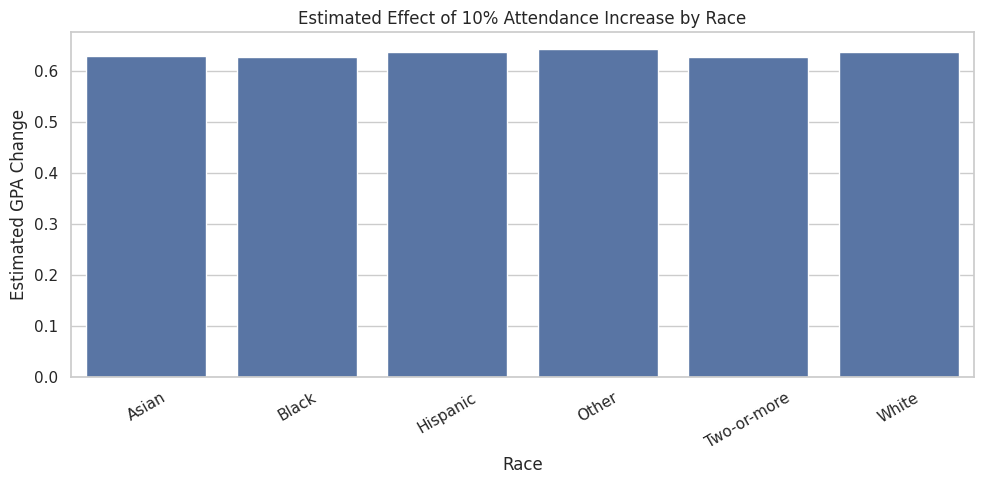

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=race_effect,
    x="Race",
    y="Mean_Effect"
)

plt.xlabel("Race")
plt.ylabel("Estimated GPA Change")
plt.title(
    "Estimated Effect of 10% Attendance Increase by Race"
)

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()



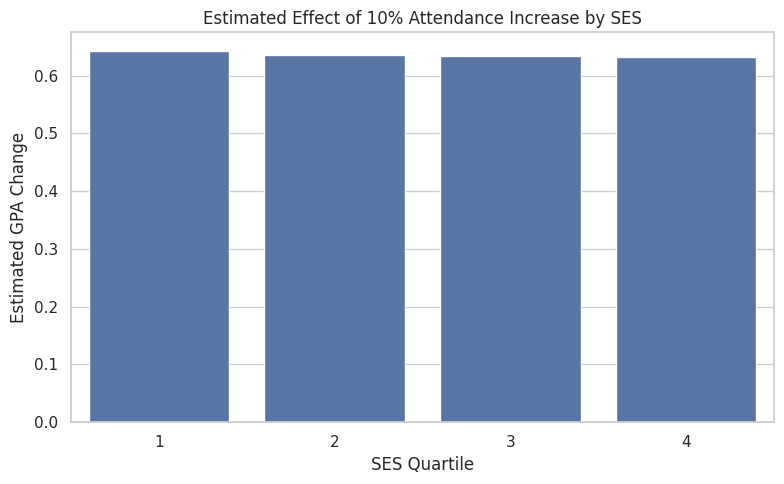

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=ses_effect,
    x="SES_Quartile",
    y="Mean_Effect"
)

plt.xlabel("SES Quartile")
plt.ylabel("Estimated GPA Change")
plt.title(
    "Estimated Effect of 10% Attendance Increase by SES"
)

plt.tight_layout()
plt.show()

In [ ]:
print(df.columns.tolist())

['Age', 'Grade', 'Gender', 'Race', 'SES_Quartile', 'ParentalEducation', 'SchoolType', 'Locale', 'TestScore_Math', 'TestScore_Reading', 'TestScore_Science', 'GPA', 'AttendanceRate', 'StudyHours', 'InternetAccess', 'Extracurricular', 'PartTimeJob', 'ParentSupport', 'Romantic', 'FreeTime', 'GoOut', 'Performance']


In [ ]:
cat_model.save_model("catboost_student_performance.cbm")


In [ ]:
import pickle

with open("encoders.pkl", "wb") as f:
    pickle.dump(label_encoders, f)